In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [2]:
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X.astype(np.float32) / 255

y_train, y_test = y[:60000].astype(int), y[60000:].astype(int)
X_train, X_test = X[:60000], X[60000:]

print("Обучающая выборка:", X_train.shape, y_train.shape)
print("Тестовая выборка:", X_test.shape, y_test.shape)
print("Размер изображения:", (28, 28))

Обучающая выборка: (60000, 784) (60000,)
Тестовая выборка: (10000, 784) (10000,)
Размер изображения: (28, 28)


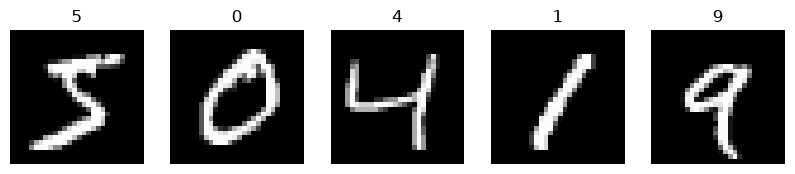

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(str(y_train[i]))
    ax.axis("off")
plt.show()

In [16]:
class TwoLayerNet:
    def __init__(self, input_dim=784, hidden_dim=300, num_classes=10, seed=42):
        np.random.seed(seed)

        self.W1 = (np.random.randn(input_dim, hidden_dim) * 0.01).astype(np.float32)
        self.b1 = np.zeros(hidden_dim, dtype=np.float32)

        self.W2 = (np.random.randn(hidden_dim, num_classes) * 0.01).astype(np.float32)
        self.b2 = np.zeros(num_classes, dtype=np.float32)

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = np.maximum(0, self.Z1)

        self.Z2 = self.A1 @ self.W2 + self.b2

        exp_Z2 = np.exp(self.Z2 - self.Z2.max(axis=1, keepdims=True))
        self.P = exp_Z2 / exp_Z2.sum(axis=1, keepdims=True)

        return self.P

    def loss_and_grads(self, X, y):
        P = self.forward(X)
        m = len(y)

        loss = -np.log(P[np.arange(m), y] + 1e-12).mean()

        dZ2 = P.copy()
        dZ2[np.arange(m), y] -= 1
        dZ2 /= m

        dW2 = self.A1.T @ dZ2
        db2 = dZ2.sum(axis=0)

        dZ1 = (dZ2 @ self.W2.T) * (self.Z1 > 0)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0)

        return loss, dW1, db1, dW2, db2

    def step(self, dW1, db1, dW2, db2, lr):
        self.W1 -= lr * dW1
        self.b1 -= lr * db1

        self.W2 -= lr * dW2
        self.b2 -= lr * db2

    def predict(self, X, batch_size=1024):
        predictions = []

        for start in range(0, len(X), batch_size):
            P = self.forward(X[start:start + batch_size])
            predictions.append(P.argmax(axis=1))

        return np.concatenate(predictions)


def classification_error(net, X, y):
    return 100 * np.mean(net.predict(X) != y)

In [17]:
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20

model = TwoLayerNet(hidden_dim=300)

for epoch in range(1, EPOCHS + 1):
    start_time = time.perf_counter()
    indices = np.random.permutation(len(X_train))

    for start in range(0, len(indices), BATCH_SIZE):
        batch = indices[start:start + BATCH_SIZE]

        loss, dW1, db1, dW2, db2 = model.loss_and_grads(
            X_train[batch], y_train[batch]
        )

        model.step(dW1, db1, dW2, db2, LEARNING_RATE)

    error = classification_error(model, X_train, y_train)
    elapsed = time.perf_counter() - start_time

    print(f"Эпоха {epoch}: ошибка {error}%, время {elapsed} с")

Эпоха 1: ошибка 8.263333333333334%, время 1.1458192000000054 с
Эпоха 2: ошибка 5.665%, время 1.4243631999997888 с
Эпоха 3: ошибка 4.3116666666666665%, время 1.60507460000008 с
Эпоха 4: ошибка 3.4283333333333332%, время 1.2584140999997544 с
Эпоха 5: ошибка 3.09%, время 1.4126131000002715 с
Эпоха 6: ошибка 2.355%, время 1.5344655999997485 с
Эпоха 7: ошибка 2.03%, время 1.7073977999998533 с
Эпоха 8: ошибка 1.8466666666666667%, время 1.4021331000003556 с
Эпоха 9: ошибка 1.5483333333333333%, время 1.2049935000004552 с
Эпоха 10: ошибка 1.4433333333333334%, время 1.0542746999999508 с
Эпоха 11: ошибка 1.145%, время 1.4271898999995756 с
Эпоха 12: ошибка 1.18%, время 1.365241700000297 с
Эпоха 13: ошибка 0.89%, время 1.0934981999998854 с
Эпоха 14: ошибка 0.8816666666666667%, время 1.1112244000005376 с
Эпоха 15: ошибка 0.7716666666666667%, время 0.9620936000001166 с
Эпоха 16: ошибка 0.6533333333333333%, время 0.947686700000304 с
Эпоха 17: ошибка 0.5833333333333334%, время 0.9708183000002464 с
Эпох

In [18]:
test_error = classification_error(model, X_test, y_test)
print("Тестовая ошибка классификации:", test_error, "%")
print("Тестовая точность:", 100 - test_error, "%")

Тестовая ошибка классификации: 1.9800000000000002 %
Тестовая точность: 98.02 %


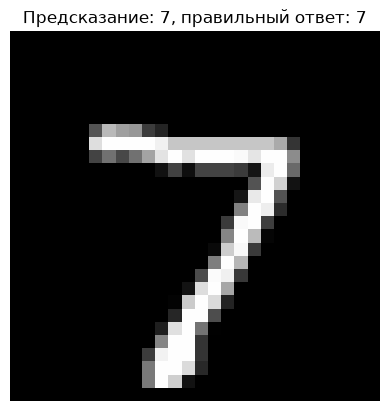

In [19]:
i = 0

image = X_test[i]
prediction = model.predict(X_test[i:i+1])[0]

plt.imshow(image.reshape(28, 28), cmap="gray")
plt.title(f"Предсказание: {prediction}, правильный ответ: {y_test[i]}")
plt.axis("off")
plt.show()

In [20]:
#экспорт в html
import nbformat
from nbconvert import HTMLExporter

notebook = nbformat.read("HW1.ipynb", as_version=4)
html, _ = HTMLExporter().from_notebook_node(notebook)

with open("HW1.html", "w", encoding="utf-8") as f:
    f.write(html)